<a href="https://colab.research.google.com/github/AyaanMahajan/econ3916/blob/main/ECON3916FINAL.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Econ 3916 Midterm Project — Econometric Foundation

**Income and Life Expectancy Across Countries in 2007**  
Ayaan Mahajan · ECON 3916 · November 9, 2026

This notebook follows the project rubric in order. Every number used in the report is produced here.


## Start here

The project asks one small question: **How is GDP per capita related to life expectancy across countries in 2007 after accounting for population size and broad region?**

The dependent variable is life expectancy at birth in years. The main explanatory variable is GDP per capita. I use the natural log of GDP per capita because the relationship rises much faster at low income levels and flattens at high income levels. I also control for population size and broad region.


## Setup
Imports only.


In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.outliers_influence import variance_inflation_factor

pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
plt.rcParams.update({"font.size": 10.5, "axes.titlesize": 12})

Path("figures").mkdir(exist_ok=True)


## Data provenance

The working file is a **teaching extract of Gapminder data** distributed through Plotly. The extract contains country-level life expectancy, population and GDP per capita in five-year steps and ends in 2007. Gapminder itself combines data from several original sources for global comparisons, so the Plotly CSV is not the original collector of the underlying statistics.

The file used here was downloaded on November 3, 2026. I also keep the source URL in the notebook so the analysis can be reproduced without emailing me for a file.


In [2]:
SOURCE_URL = "https://raw.githubusercontent.com/plotly/datasets/master/gapminderDataFiveYear.csv"
ORIGINAL_SOURCE_URL = "https://www.gapminder.org/data/"
DOWNLOAD_DATE = "2026-11-03"
FILE_NAME = "data/ECON3916_gapminder_2007.csv"

print("Teaching extract:", SOURCE_URL)
print("Original data source:", ORIGINAL_SOURCE_URL)
print("Downloaded:", DOWNLOAD_DATE)


Teaching extract: https://raw.githubusercontent.com/plotly/datasets/master/gapminderDataFiveYear.csv
Original data source: https://www.gapminder.org/data/
Downloaded: 2026-11-03


**Who collected it, for what purpose, what is missing and why?**

Gapminder combines data from several statistical sources to make long-run global comparisons easier to understand. The teaching extract keeps a balanced set of 142 countries and has complete values for the variables used here in 2007. That does **not** mean every country or territory in the world is represented. The missingness I care about is therefore coverage missingness rather than blank cells inside the final table. I would not call that MCAR because inclusion depends on whether a usable historical series was available. I treat it as closer to **MNAR**, since countries with weaker statistical systems may be less likely to appear in a clean historical teaching extract. I cannot test that mechanism directly, so I treat it as a limitation.


## Section 1: The Question and the Data (20 pts)

My question is: **Across countries in 2007, how is GDP per capita related to life expectancy at birth after accounting for population size and broad region?**

This matters because income and health are two basic measures of development. A richer country usually has more resources for food, housing, sanitation and medical care, but the relationship should not be perfectly linear. An extra dollar matters much more in a very poor country than in a very rich one. The result is useful for anyone comparing development across countries because it shows how much of the cross-country gap in life expectancy lines up with income and how much remains after broad regional differences are held fixed.


In [3]:
# Load the saved 2007 file if it exists. If someone clones only the notebook,
# the same teaching extract can be downloaded from SOURCE_URL.
local_path = Path(FILE_NAME)
if local_path.exists():
    df = pd.read_csv(local_path)
else:
    raw = pd.read_csv(SOURCE_URL)
    df = raw.loc[raw["year"] == 2007].copy()

# Main transformations
# GDP and population are very skewed, so I use natural logs in the model.
df["log_gdp"] = np.log(df["gdpPercap"])
df["log_pop"] = np.log(df["pop"])

# Oceania only has Australia and New Zealand, so I merge it with Asia.
df["region"] = df["continent"].replace({"Asia": "Asia-Pacific", "Oceania": "Asia-Pacific"})

print("Rows:", len(df))
print("Columns:", df.shape[1])
print("Missing values in original columns:")
print(df[["country","continent","year","lifeExp","pop","gdpPercap"]].isna().sum())
print("\nRegion counts:")
print(df["region"].value_counts())


Rows: 142
Columns: 9
Missing values in original columns:
country      0
continent    0
year         0
lifeExp      0
pop          0
gdpPercap    0
dtype: int64

Region counts:
region
Africa          52
Asia-Pacific    35
Europe          30
Americas        25
Name: count, dtype: int64


In [4]:
# Summary statistics used in the report
summary_table = pd.DataFrame({
    "Variable (units)": [
        "Life expectancy (years)",
        "GDP per capita (inflation-adjusted US$)",
        "Population (people)"
    ],
    "Mean": [df.lifeExp.mean(), df.gdpPercap.mean(), df["pop"].mean()],
    "Median": [df.lifeExp.median(), df.gdpPercap.median(), df["pop"].median()],
    "SD": [df.lifeExp.std(), df.gdpPercap.std(), df["pop"].std()],
    "Min": [df.lifeExp.min(), df.gdpPercap.min(), df["pop"].min()],
    "Max": [df.lifeExp.max(), df.gdpPercap.max(), df["pop"].max()],
    "N": [df.lifeExp.count(), df.gdpPercap.count(), df["pop"].count()]
})
summary_table


,Variable (units),Mean,Median,SD,Min,Max,N
0,Life expectancy (years),67.007,71.935,12.073,39.613,82.603,142
1,GDP per capita (inflation-adjusted US$),"11,680.072","6,124.371","12,859.937",277.552,"49,357.190",142
2,Population (people),"44,021,219.570","10,517,531.000","147,621,397.904","199,579.000","1,318,683,096.000",142


In [5]:
# Section 1 self-check
UNIT = "country in 2007"
OUTCOME = "lifeExp"
MAIN_X = "log_gdp"
CONTROLS = ["log_pop", "region"]

print(f"Unit: {UNIT}")
print(f"Outcome: {OUTCOME}")
print(f"Main X: {MAIN_X}")
print(f"Controls: {CONTROLS}")
print(f"Rows: {len(df):,}")
print("All model variables use 2007 country-level observations.")


Unit: country in 2007
Outcome: lifeExp
Main X: log_gdp
Controls: ['log_pop', 'region']
Rows: 142
All model variables use 2007 country-level observations.


**Control check before moving on**

1. **Population:** I include log population because country scale can be related to both income per person and health outcomes. Larger countries can have different agglomeration, urbanization and market-size effects on income, while scale can also change how health systems, infrastructure and disease transmission work. It is not my main variable, and the model shows its coefficient is close to zero. It would be a bad control if the income measure itself caused population on the path to life expectancy in the same period.
2. **Region:** Broad region is the clearer confounder. Geography, institutions, disease environment and long-run development patterns can affect both GDP per capita and life expectancy. GDP per capita cannot cause a country to move continents, so region is not downstream of the main explanatory variable.
3. **Oceania:** I do not estimate a separate Oceania dummy because it has only two countries. I combine Australia and New Zealand with Asia as **Asia-Pacific** and later check that keeping Oceania separate does not change the GDP result much.
4. All variables are country-level measures from 2007. This is not a policy before-and-after question, so there is no missing pre-period.


## Section 2: Descriptive Evidence (20 pts)

Before fitting the model I look at the outcome and then the relationship between income and life expectancy. GDP per capita is strongly right-skewed, which is why the model uses its natural log. Life expectancy itself is measured in years and is not transformed.


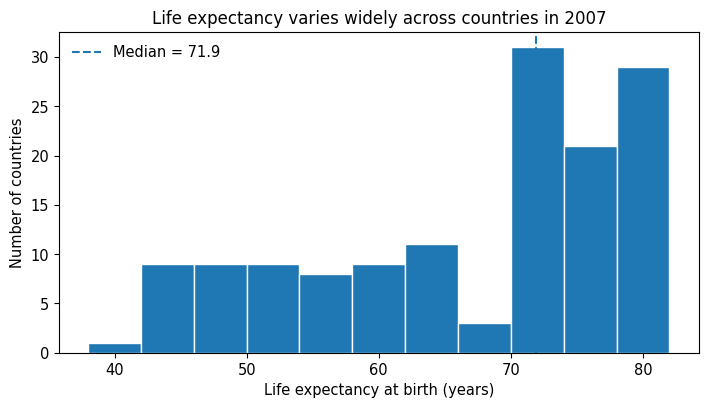

In [6]:
# Figure 1: outcome distribution
fig, ax = plt.subplots(figsize=(7.2, 4.2))
ax.hist(df["lifeExp"], bins=np.arange(38, 86, 4), edgecolor="white")
ax.axvline(df["lifeExp"].median(), linestyle="--", linewidth=1.5, label=f"Median = {df['lifeExp'].median():.1f}")
ax.set_xlabel("Life expectancy at birth (years)")
ax.set_ylabel("Number of countries")
ax.set_title("Life expectancy varies widely across countries in 2007")
ax.set_ylim(bottom=0)
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig("figures/figure1_life_expectancy.png", dpi=180)
plt.show()


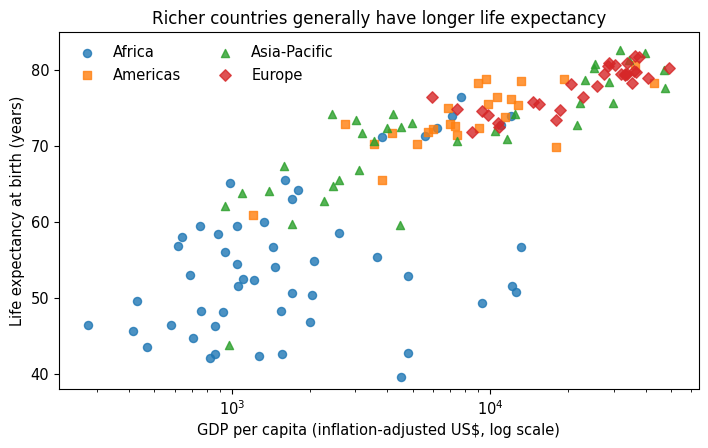

Correlation between log GDP per capita and life expectancy: 0.809

Mean life expectancy by GDP-per-capita quartile:
gdp_quartile
Q1   53.120
Q2   64.390
Q3   71.560
Q4   79.010
Name: lifeExp, dtype: float64


In [7]:
# Figure 2: main descriptive relationship
fig, ax = plt.subplots(figsize=(7.2, 4.6))
markers = {"Africa":"o", "Americas":"s", "Asia-Pacific":"^", "Europe":"D"}
for reg, g in df.groupby("region"):
    ax.scatter(g["gdpPercap"], g["lifeExp"], label=reg, marker=markers[reg], s=34, alpha=0.80)
ax.set_xscale("log")
ax.set_xlabel("GDP per capita (inflation-adjusted US$, log scale)")
ax.set_ylabel("Life expectancy at birth (years)")
ax.set_title("Richer countries generally have longer life expectancy")
ax.set_ylim(38, 85)
ax.legend(frameon=False, ncol=2)
fig.tight_layout()
fig.savefig("figures/figure2_gdp_life.png", dpi=180)
plt.show()

# Simple descriptive comparisons used in the text
print("Correlation between log GDP per capita and life expectancy:", round(df[["log_gdp","lifeExp"]].corr().iloc[0,1], 3))
q = pd.qcut(df["gdpPercap"], 4, labels=["Q1", "Q2", "Q3", "Q4"])
print("\nMean life expectancy by GDP-per-capita quartile:")
print(df.assign(gdp_quartile=q).groupby("gdp_quartile", observed=False)["lifeExp"].mean().round(2))


**What the figures show**

Figure 1 shows a large spread in life expectancy. The median is about 71.9 years, but the lowest country is below 40 years and the highest is above 82. Figure 2 shows a strong positive relationship between income and life expectancy, but the horizontal spacing makes the main point clearer: the gains are steep at low income levels and much flatter at high income levels. That is the reason I use **log GDP per capita** instead of raw GDP per capita.

**Figure 1 caption:** Life expectancy differs by more than 40 years across the 142 countries in the 2007 teaching extract. Source: Gapminder teaching extract distributed through Plotly.

**Figure 2 caption:** Life expectancy rises strongly with GDP per capita, especially at lower income levels; the relationship is flatter among richer countries. Source: Gapminder teaching extract distributed through Plotly.


## Section 3: The Model (25 pts)

The main model is:

**Life expectancy = β0 + β1 log(GDP per capita) + β2 log(population) + region indicators + error**

Africa is the reference region. The region indicators compare the Americas, Asia-Pacific and Europe with Africa after GDP per capita and population are held fixed. I first fit a simple model with only log GDP per capita and then the main multivariate model.


In [8]:
# Column 1: GDP only
model_gdp = smf.ols("lifeExp ~ log_gdp", data=df).fit()
model_gdp_hc3 = model_gdp.get_robustcov_results(cov_type="HC3")

# Column 2: main mode
model_main = smf.ols("lifeExp ~ log_gdp + log_pop + C(region)", data=df).fit()
model_main_hc3 = model_main.get_robustcov_results(cov_type="HC3")

# Helper for named robust resulgs
def robust_frame(model, robust):
    ci = robust.conf_int()
    return pd.DataFrame({
        "term": model.model.exog_names,
        "coefficient": model.params,
        "robust_se": robust.bse,
        "p_value": robust.pvalues,
        "ci_low": ci[:,0],
        "ci_high": ci[:,1]
    }).set_index("term")

main_results = robust_frame(model_main, model_main_hc3)
gdp_results = robust_frame(model_gdp, model_gdp_hc3)

# Formatted regression table for the report appendix
def fmt(coef, se):
    return f"{coef:.2f}\n({se:.2f})"

terms = [
    ("log GDP per capita", "log_gdp"),
    ("log population", "log_pop"),
    ("Americas", "C(region)[T.Americas]"),
    ("Asia-Pacific", "C(region)[T.Asia-Pacific]"),
    ("Europe", "C(region)[T.Europe]"),
    ("Constant", "Intercept")
]
rows=[]
for label, term in terms:
    c1 = ""
    if term in gdp_results.index:
        c1 = fmt(gdp_results.loc[term,"coefficient"], gdp_results.loc[term,"robust_se"])
    c2 = fmt(main_results.loc[term,"coefficient"], main_results.loc[term,"robust_se"])
    rows.append([label, c1, c2])
reg_table = pd.DataFrame(rows, columns=["Term", "(1) GDP only", "(2) Main"])
reg_table.loc[len(reg_table)] = ["N", f"{int(model_gdp.nobs)}", f"{int(model_main.nobs)}"]
reg_table.loc[len(reg_table)] = ["R-squared", f"{model_gdp.rsquared:.3f}", f"{model_main.rsquared:.3f}"]
reg_table


,Term,(1) GDP only,(2) Main
0,log GDP per capita,7.20\n(0.34),4.70\n(0.68)
1,log population,,0.03\n(0.39)
2,Americas,,11.57\n(2.03)
3,Asia-Pacific,,10.15\n(2.17)
4,Europe,,11.08\n(2.52)
5,Constant,4.95\n(3.16),19.14\n(8.65)
6,N,142,142
7,R-squared,0.654,0.767


In [9]:
# Interpret the main coefficient in easier units
beta_gdp = main_results.loc["log_gdp", "coefficient"]
gdp_ci_low = main_results.loc["log_gdp", "ci_low"]
gdp_ci_high = main_results.loc["log_gdp", "ci_high"]

doubling_effect = beta_gdp * np.log(2)
doubling_low = gdp_ci_low * np.log(2)
doubling_high = gdp_ci_high * np.log(2)

tenpct_effect = beta_gdp * np.log(1.10)

print(f"Main log-GDP coefficient: {beta_gdp:.3f}")
print(f"HC3 SE: {main_results.loc['log_gdp','robust_se']:.3f}")
print(f"95% CI for log-GDP coefficient: [{gdp_ci_low:.3f}, {gdp_ci_high:.3f}]")
print(f"Effect associated with doubling GDP per capita: {doubling_effect:.3f} years")
print(f"95% CI for doubling effect: [{doubling_low:.3f}, {doubling_high:.3f}] years")
print(f"Effect associated with a 10% increase in GDP per capita: {tenpct_effect:.3f} years")
print(f"Main-model R-squared: {model_main.rsquared:.3f}")


Main log-GDP coefficient: 4.702
HC3 SE: 0.678
95% CI for log-GDP coefficient: [3.361, 6.042]
Effect associated with doubling GDP per capita: 3.259 years
95% CI for doubling effect: [2.330, 4.188] years
Effect associated with a 10% increase in GDP per capita: 0.448 years
Main-model R-squared: 0.767


**Model interpretation**

The main GDP coefficient is positive. Because GDP is logged, I do not interpret 4.70 as “one extra dollar adds 4.70 years.” A more useful interpretation is a doubling: holding population and broad region fixed, **doubling GDP per capita is associated with about 3.26 more years of life expectancy**. The HC3 95% confidence interval is about **2.33 to 4.19 years**, so the positive association is estimated fairly precisely.

The region coefficients are also large. Holding GDP per capita and population fixed, a European country is estimated to have about **11.1 more years** of life expectancy than an otherwise comparable African country, with a robust 95% interval of about **6.1 to 16.1 years**. I do not read this as a causal “Europe effect.” It is a broad control picking up many differences that are not measured separately.

Population is included because country scale can affect both income and health conditions, but its coefficient is almost zero once GDP and region are included. That is useful because it shows the main GDP result is not being driven by the fact that some countries are simply much larger than others.


## Section 4: Diagnostics (20 pts)

I check the main model using the Topic 14 tools: residual plots, a constant-variance test, variance inflation factors and Cook's distance. Because the variance test rejects constant variance, the report uses **HC3 robust standard errors**.


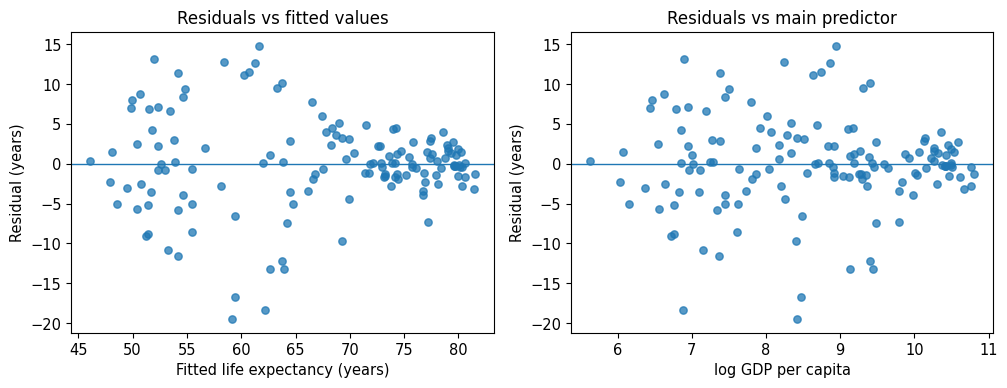

Breusch-Pagan LM statistic: 38.474
Breusch-Pagan LM p-value: 0.00000030
Breusch-Pagan F statistic: 10.109
Breusch-Pagan F p-value: 0.00000003


In [10]:
# Residual plots
fitted = model_main.fittedvalues
resid = model_main.resid

fig, axes = plt.subplots(1, 2, figsize=(10.2, 4.0))
axes[0].scatter(fitted, resid, alpha=0.75, s=28)
axes[0].axhline(0, linewidth=1)
axes[0].set_xlabel("Fitted life expectancy (years)")
axes[0].set_ylabel("Residual (years)")
axes[0].set_title("Residuals vs fitted values")

axes[1].scatter(df["log_gdp"], resid, alpha=0.75, s=28)
axes[1].axhline(0, linewidth=1)
axes[1].set_xlabel("log GDP per capita")
axes[1].set_ylabel("Residual (years)")
axes[1].set_title("Residuals vs main predictor")

fig.tight_layout()
fig.savefig("figures/figureA1_residuals.png", dpi=180)
plt.show()

# Breusch-Pagan test
bp_lm, bp_lm_p, bp_f, bp_f_p = het_breuschpagan(model_main.resid, model_main.model.exog)
print(f"Breusch-Pagan LM statistic: {bp_lm:.3f}")
print(f"Breusch-Pagan LM p-value: {bp_lm_p:.8f}")
print(f"Breusch-Pagan F statistic: {bp_f:.3f}")
print(f"Breusch-Pagan F p-value: {bp_f_p:.8f}")


In [11]:
# VIFS
X = pd.DataFrame(model_main.model.exog, columns=model_main.model.exog_names)
vif_rows=[]
for i, col in enumerate(X.columns):
    if col != "Intercept":
        vif_rows.append([col, variance_inflation_factor(X.values, i)])
vif_table = pd.DataFrame(vif_rows, columns=["term", "VIF"])
vif_table



,term,VIF
0,C(region)[T.Americas],1.657
1,C(region)[T.Asia-Pacific],1.838
2,C(region)[T.Europe],2.444
3,log_gdp,2.051
4,log_pop,1.137


In [12]:
# Influence check using Cook's distance
influence = model_main.get_influence()
cooks = influence.cooks_distance[0]
cutoff = 4 / len(df)

df_influence = df[["country","lifeExp","gdpPercap","pop","region"]].copy()
df_influence["cooks_d"] = cooks
df_influence["leverage"] = influence.hat_matrix_diag
df_influence["studentized_resid"] = influence.resid_studentized_external

top_influence = df_influence.sort_values("cooks_d", ascending=False).head(10)
print("Cook's-distance cutoff 4/n =", round(cutoff, 4))
print("Observations above cutoff =", int((cooks > cutoff).sum()))
top_influence


Cook's-distance cutoff 4/n = 0.0282
Observations above cutoff = 12


,country,lifeExp,gdpPercap,pop,region,cooks_d,leverage,studentized_resid
11,Afghanistan,43.828,974.580,"31,889,923.000",Asia-Pacific,0.103,0.058,-3.292
1463,Swaziland,39.613,"4,513.481","1,133,066.000",Africa,0.068,0.035,-3.477
1271,Reunion,76.442,"7,670.123","798,094.000",Africa,0.054,0.047,2.616
1415,South Africa,49.339,"9,269.658","43,997,828.000",Africa,0.053,0.057,-2.338
491,Equatorial Guinea,51.579,"12,154.090","551,201.000",Africa,0.050,0.063,-2.145
167,Botswana,50.728,"12,569.852","1,639,131.000",Africa,0.048,0.052,-2.322
1307,Sao Tome and Principe,65.528,"1,598.435","199,579.000",Africa,0.046,0.066,1.999
47,Angola,42.731,"4,797.231","12,420,476.000",Africa,0.040,0.029,-2.940
323,Comoros,65.152,986.148,"710,960.000",Africa,0.040,0.044,2.310
467,Egypt,71.338,"5,581.181","80,264,543.000",Africa,0.035,0.054,1.941


In [13]:
# What happens if I remove the single most influential country?
most_influential_country = top_influence.iloc[0]["country"]
df_no_top = df.loc[df["country"] != most_influential_country].copy()
model_no_top = smf.ols("lifeExp ~ log_gdp + log_pop + C(region)", data=df_no_top).fit()
model_no_top_hc3 = model_no_top.get_robustcov_results(cov_type="HC3")
no_top_results = robust_frame(model_no_top, model_no_top_hc3)

print("Most influential country:", most_influential_country)
print("Main log-GDP coefficient:", round(main_results.loc["log_gdp","coefficient"], 3))
print("Without most influential country:", round(no_top_results.loc["log_gdp","coefficient"], 3))

# Sensitivity check: keep Oceania separate instead of merging it with Asia
model_sep = smf.ols("lifeExp ~ log_gdp + log_pop + C(continent)", data=df).fit()
model_sep_hc3 = model_sep.get_robustcov_results(cov_type="HC3")
sep_results = robust_frame(model_sep, model_sep_hc3)
print("\nGDP coefficient with Oceania separate:", round(sep_results.loc["log_gdp","coefficient"], 3))


Most influential country: Afghanistan
Main log-GDP coefficient: 4.702
Without most influential country: 4.407

GDP coefficient with Oceania separate: 4.642


**Diagnostic interpretation**

The residual plots do not show a strong leftover curve against log GDP, which supports using the log transformation. The spread is not constant, though. The Breusch-Pagan test rejects constant variance very strongly, so the classical OLS standard errors are not the ones I report. I use **HC3 robust standard errors** throughout the main regression table.

The VIFs are all low, with the largest around 2.4. That means the wide or narrow confidence intervals are not being driven by serious multicollinearity.

Cook's distance flags several countries, with **Afghanistan** the most influential observation. I do not delete it from the main sample because it is a real country and not a data-entry error. As a sensitivity check, removing Afghanistan changes the log-GDP coefficient from about **4.70 to 4.41**, so the positive result is not dependent on that one row.

Finally, keeping Oceania as its own two-country category gives a log-GDP coefficient of about **4.64**, very close to the **4.70** estimate in the merged Asia-Pacific version. That makes me more comfortable that the merge is not creating the main result.


## Section 5: Threats and Conclusion (10 pts)

For the GDP coefficient to be causal, countries with the same population and broad region would have to differ in GDP per capita for reasons unrelated to every other determinant of life expectancy. That is not realistic. Education, health systems, inequality, conflict, institutions, sanitation and many other factors can affect both national income and health. Some of them may also be channels through which income changes health, which makes control selection difficult.

There is also a measurement problem. Gapminder is useful for broad international comparisons, but it combines sources and sometimes fills historical gaps. The teaching extract is also a selected sample that ends in 2007. My result therefore should be described as a **conditional association**, not the causal effect of making a country richer.

The main finding is still clear. Countries with higher GDP per capita tend to have longer life expectancy, even after population size and broad region are held fixed. In the main model, doubling GDP per capita is associated with about **3.26 additional years** of life expectancy, with a robust 95% interval of about **2.33 to 4.19 years**. The result survives the main influence and region-coding checks, but it should not be read as proof that doubling income by itself would add exactly that many years.

With another month, I would improve the project by joining a carefully sourced education measure and a health-system measure for the same year, then checking whether the GDP coefficient changes. I would also use a larger panel over multiple years with year and country effects. That would give more information than one cross-section and would make it easier to separate persistent country differences from changes over time.


## Appendix

The first table is the formatted regression table used in the report. The diagnostic plots are saved in the `figures/` folder by the code above.


In [14]:
print("Table A1. Life expectancy regressed on log GDP per capita and controls")
display(reg_table)
print("\nNote: HC3 robust standard errors are in parentheses. Africa is the reference region. Column 2 is the main model.")

print("\nTop influential observations:")
display(top_influence[["country","cooks_d","leverage","studentized_resid"]].head(10))


Table A1. Life expectancy regressed on log GDP per capita and controls


,Term,(1) GDP only,(2) Main
0,log GDP per capita,7.20\n(0.34),4.70\n(0.68)
1,log population,,0.03\n(0.39)
2,Americas,,11.57\n(2.03)
3,Asia-Pacific,,10.15\n(2.17)
4,Europe,,11.08\n(2.52)
5,Constant,4.95\n(3.16),19.14\n(8.65)
6,N,142,142
7,R-squared,0.654,0.767



Note: HC3 robust standard errors are in parentheses. Africa is the reference region. Column 2 is the main model.

Top influential observations:


,country,cooks_d,leverage,studentized_resid
11,Afghanistan,0.103,0.058,-3.292
1463,Swaziland,0.068,0.035,-3.477
1271,Reunion,0.054,0.047,2.616
1415,South Africa,0.053,0.057,-2.338
491,Equatorial Guinea,0.050,0.063,-2.145
167,Botswana,0.048,0.052,-2.322
1307,Sao Tome and Principe,0.046,0.066,1.999
47,Angola,0.040,0.029,-2.940
323,Comoros,0.040,0.044,2.310
467,Egypt,0.035,0.054,1.941


## Numbers my report quotes

Every number in the report is printed here so the grader can match the report to the notebook.


In [15]:
# Convenient named values
main_ci = model_main_hc3.conf_int()
name_to_i = {name:i for i,name in enumerate(model_main.model.exog_names)}

def ci_for(term):
    i = name_to_i[term]
    return main_ci[i,0], main_ci[i,1]

europe_lo, europe_hi = ci_for("C(region)[T.Europe]")

REPORT_NUMBERS = {
    "Section 1: final sample N": int(len(df)),
    "Section 1: life expectancy mean": round(df.lifeExp.mean(), 3),
    "Section 1: life expectancy median": round(df.lifeExp.median(), 3),
    "Section 1: life expectancy SD": round(df.lifeExp.std(), 3),
    "Section 1: life expectancy min": round(df.lifeExp.min(), 3),
    "Section 1: life expectancy max": round(df.lifeExp.max(), 3),
    "Section 1: GDP per capita mean": round(df.gdpPercap.mean(), 3),
    "Section 1: GDP per capita median": round(df.gdpPercap.median(), 3),
    "Section 1: GDP per capita SD": round(df.gdpPercap.std(), 3),
    "Section 1: GDP per capita min": round(df.gdpPercap.min(), 3),
    "Section 1: GDP per capita max": round(df.gdpPercap.max(), 3),
    "Section 1: population mean": round(df['pop'].mean(), 3),
    "Section 1: population median": round(df['pop'].median(), 3),
    "Section 1: population SD": round(df['pop'].std(), 3),
    "Section 1: population min": int(df['pop'].min()),
    "Section 1: population max": int(df['pop'].max()),
    "Section 1: Africa count": int((df.region == "Africa").sum()),
    "Section 1: Americas count": int((df.region == "Americas").sum()),
    "Section 1: Asia-Pacific count": int((df.region == "Asia-Pacific").sum()),
    "Section 1: Europe count": int((df.region == "Europe").sum()),
    "Section 2: log GDP-life expectancy correlation": round(df[["log_gdp","lifeExp"]].corr().iloc[0,1], 3),
    "Section 2: Q1 GDP mean life expectancy": round(df.assign(q=pd.qcut(df.gdpPercap,4)).groupby('q', observed=False).lifeExp.mean().iloc[0], 3),
    "Section 2: Q4 GDP mean life expectancy": round(df.assign(q=pd.qcut(df.gdpPercap,4)).groupby('q', observed=False).lifeExp.mean().iloc[-1], 3),
    "Section 3: GDP-only log GDP coefficient": round(gdp_results.loc['log_gdp','coefficient'], 3),
    "Section 3: GDP-only log GDP HC3 SE": round(gdp_results.loc['log_gdp','robust_se'], 3),
    "Section 3: GDP-only intercept": round(gdp_results.loc['Intercept','coefficient'], 3),
    "Section 3: GDP-only intercept HC3 SE": round(gdp_results.loc['Intercept','robust_se'], 3),
    "Section 3: GDP-only R2": round(model_gdp.rsquared, 3),
    "Section 3: main log GDP coefficient": round(beta_gdp, 3),
    "Section 3: main log GDP HC3 SE": round(main_results.loc['log_gdp','robust_se'], 3),
    "Section 3: main log GDP CI low": round(gdp_ci_low, 3),
    "Section 3: main log GDP CI high": round(gdp_ci_high, 3),
    "Section 3: doubling GDP effect": round(doubling_effect, 3),
    "Section 3: doubling GDP CI low": round(doubling_low, 3),
    "Section 3: doubling GDP CI high": round(doubling_high, 3),
    "Section 3: 10 percent GDP effect": round(tenpct_effect, 3),
    "Section 3: Americas coefficient": round(main_results.loc['C(region)[T.Americas]','coefficient'], 3),
    "Section 3: Americas HC3 SE": round(main_results.loc['C(region)[T.Americas]','robust_se'], 3),
    "Section 3: Asia-Pacific coefficient": round(main_results.loc['C(region)[T.Asia-Pacific]','coefficient'], 3),
    "Section 3: Asia-Pacific HC3 SE": round(main_results.loc['C(region)[T.Asia-Pacific]','robust_se'], 3),
    "Section 3: Europe coefficient": round(main_results.loc['C(region)[T.Europe]','coefficient'], 3),
    "Section 3: Europe HC3 SE": round(main_results.loc['C(region)[T.Europe]','robust_se'], 3),
    "Section 3: Europe CI low": round(europe_lo, 3),
    "Section 3: Europe CI high": round(europe_hi, 3),
    "Section 3: log population coefficient": round(main_results.loc['log_pop','coefficient'], 3),
    "Section 3: log population HC3 SE": round(main_results.loc['log_pop','robust_se'], 3),
    "Section 3: main intercept": round(main_results.loc['Intercept','coefficient'], 3),
    "Section 3: main intercept HC3 SE": round(main_results.loc['Intercept','robust_se'], 3),
    "Section 3: main model R2": round(model_main.rsquared, 3),
    "Section 4: BP LM statistic": round(bp_lm, 3),
    "Section 4: BP LM p-value": bp_lm_p,
    "Section 4: max VIF": round(vif_table.VIF.max(), 3),
    "Section 4: Cook cutoff": round(cutoff, 4),
    "Section 4: observations above Cook cutoff": int((cooks > cutoff).sum()),
    "Section 4: most influential country": most_influential_country,
    "Section 4: most influential Cook D": round(top_influence.iloc[0]['cooks_d'], 3),
    "Section 4: log GDP coefficient without most influential": round(no_top_results.loc['log_gdp','coefficient'], 3),
    "Section 4: log GDP coefficient with Oceania separate": round(sep_results.loc['log_gdp','coefficient'], 3),
}

for name, value in REPORT_NUMBERS.items():
    print(f"{name}: {value}")


Section 1: final sample N: 142
Section 1: life expectancy mean: 67.007
Section 1: life expectancy median: 71.935
Section 1: life expectancy SD: 12.073
Section 1: life expectancy min: 39.613
Section 1: life expectancy max: 82.603
Section 1: GDP per capita mean: 11680.072
Section 1: GDP per capita median: 6124.371
Section 1: GDP per capita SD: 12859.937
Section 1: GDP per capita min: 277.552
Section 1: GDP per capita max: 49357.19
Section 1: population mean: 44021219.57
Section 1: population median: 10517531.0
Section 1: population SD: 147621397.904
Section 1: population min: 199579
Section 1: population max: 1318683096
Section 1: Africa count: 52
Section 1: Americas count: 25
Section 1: Asia-Pacific count: 35
Section 1: Europe count: 30
Section 2: log GDP-life expectancy correlation: 0.809
Section 2: Q1 GDP mean life expectancy: 53.125
Section 2: Q4 GDP mean life expectancy: 79.009
Section 3: GDP-only log GDP coefficient: 7.203
Section 3: GDP-only log GDP HC3 SE: 0.337
Section 3: GDP-on

## Checkpoints

- Checkpoint 1: question and data source posted.
- Checkpoint 2: data loaded and summary table committed.
- Checkpoint 3: draft model committed.
- Final: notebook, report and README ready for the repository.


## Before you submit

- Notebook runs from top to bottom.
- Report uses only numbers printed by this notebook.
- At least two descriptive figures are included with finding-based captions.
- Main OLS table reports coefficients, robust standard errors, N and R-squared.
- Diagnostics include residual plots, Breusch-Pagan, VIF and Cook's distance.
- The conclusion labels the result as a conditional association, not a causal effect.
- The repository includes the notebook, report, README and either the data file or a documented download step.
